# Quadtree: Indexing Points in 2D Space
**Objectives** : Understand how a Quadtree subdivides space, visualize the effect of capacity, and perform a spatial query.

***Dataset*** : Simulated bike stations in a 1000 x 1000 m city.

## 1. Installation and Imports

In [87]:
!pip install -q numpy
!pip install -q pandas
!pip install -q matplotlib
!pip install -q e-pyquadtree

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pyquadtree import QuadTree

## 2. Generating the Dataset
The dataset is automatically regenerated following centers of interest, with some random noise added. The centers are defined by their coordinates, dispersion, and number of points. The dataset is stored in a pandas DataFrame with columns `x`, `y`, and `category`.

In [93]:

rng = np.random.default_rng(42)
centers = {"Suburbs": (300, 650, 180, 90),
            "Petit-Port": (750, 250, 40, 30),
            "City-Centre": (200, 200, 50, 60), 
            "Campus": (800, 800, 50, 20)} #(x, y, dispersion, n)
rows = []
for nom, (cx, cy, s, n) in centers.items():
    rows += [(x, y, nom) for x, y in rng.normal([cx, cy], s, size=(n, 2))]
rows += [(x, y, "New-Stations") for x, y in rng.uniform(0, 1000, size=(40, 2))]
df = pd.DataFrame(rows, columns=["x", "y", "category"])
df[["x", "y"]] = df[["x", "y"]].clip(0, 9999.9).round(2)
df.insert(0, "id", range(1, len(df) + 1))
print(df.shape)
df.head()

(240, 4)


,id,x,y,category
0,1,354.85,462.80,Suburbs
1,2,435.08,819.30,Suburbs
2,3,0.00,415.61,Suburbs
3,4,323.01,593.08,Suburbs
4,5,296.98,496.45,Suburbs


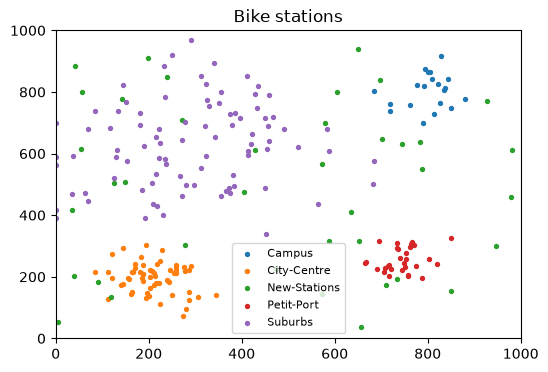

In [94]:
fig, ax = plt.subplots(figsize=(6, 4))
for q, g in df.groupby("category"):
    ax.scatter(g.x, g.y, s=8, label=q)
ax.set_xlim(0, 1000); ax.set_ylim(0, 1000)
ax.legend(fontsize=8); ax.set_title("Bike stations")
plt.show()

## 3. Building the Quadtree
`max_elements` is the capacity: beyond which, the cell divides into `x` elements. `max_depth` prevents infinite subdivision.

In [95]:
def build_qt(df, capacity=8, depth_max=8):
    qt = QuadTree(
        bbox=(0, 0, 1000, 1000),
        max_elements=capacity,
        max_depth=depth_max
    )

    qt.capacity = capacity
    qt.depth_max = depth_max

    for row in df.itertuples():
        qt.add(row.id, (row.x, row.y))
    return qt

qt = build_qt(df, capacity=8, depth_max=8)
bboxes = qt.get_all_bbox()
print("Number of nodes (rectangles) :", len(bboxes))

Number of nodes (rectangles) : 117


## 4. Visualizing the Quadtree

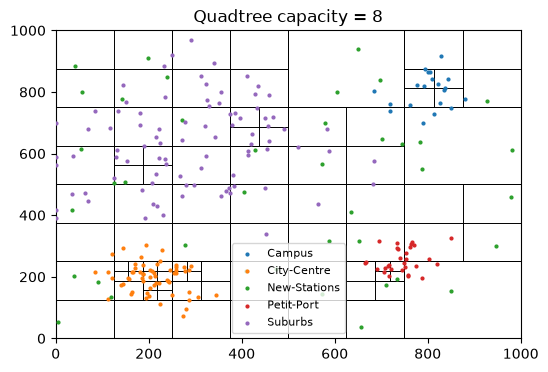

In [96]:
def tracer(df, qt, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))

    # Draw Quadtree rectangles
    for (x0, y0, x1, y1) in qt.get_all_bbox():
        ax.add_patch(Rectangle(
            (x0, y0), x1 - x0, y1 - y0,
            fill=False, edgecolor="black", linewidth=0.6
        ))

    # Draw points by neighborhood
    for q, g in df.groupby("category"):
        ax.scatter(g.x, g.y, s=4, label=q, zorder=3)

    ax.set_xlim(0, 1000)
    ax.set_ylim(0, 1000)
    ax.legend(fontsize=8)
    ax.set_title(f"Quadtree capacity = {qt.capacity}")

    return ax

tracer(df, qt)
plt.show()

The cells are **smaller where points are dense** (city-center, stations, university, port) and **larger in the periphery**, this is the whole point of an adaptive quadtree. In order to achieve the most homogeneous spatial coverage possible, the company Velonecy would benefit from filling the larges parse areas with new potential stations.